# Cambridge Residential Property Values by Neighborhood (FY2026)

Choropleth maps and supporting analysis of assessed property values across Cambridge's thirteen CDD neighborhoods, using the Cambridge Property Database (Socrata `eey2-rv59`).

## What this notebook covers

| Section | Output |
|---------|--------|
| % single-family homes | `../data/out/pct_sfh_map.png` |

## Key data decisions

**Which residential codes to include:**
The dataset uses Massachusetts state class codes. We include codes that represent occupied residential property:

| Code | Type | Included | Rationale |
|------|------|----------|-----------|
| 101 | Single-family | ✓ | Core residential |
| 102 | Condo unit | ✓ | Individual units |
| 104 | 2-family | ✓ | |
| 105 | 3-family | ✓ | |
| 106 | 4–6 unit | ✓ | |
| 109 | Apt 7+ | ✓ | |
| 111–114 | Mixed-use / other res | ✓ | |
| 121 | Other residential | ✓ | |
| 13 | Res (alternate code) | ✓ | Small count, same population |
| 199 | Condo master record | ✗ | Building-level record; including it would double-count condo assessed values alongside code 102 unit records |
| 122–123 | Frats / dorms | ✗ | Institutional, not residential market |
| 130–132 | Vacant land | ✗ | No structure |

**What these counts cover:** The residential codes above yield ~47,200 housing units and ~21,600 properties in FY2026. This represents the privately-owned residential stock — including ~1,600 deed-restricted inclusionary zoning (IZ) units and ~150 scattered-site homeownership units, which are assessed under standard residential codes. It excludes ~2,800 public housing units managed by the Cambridge Housing Authority (CHA), university-owned housing (Harvard, MIT, Lesley), and other institutionally-owned dwellings on tax-exempt land. The city's total housing stock is 58,966 units (CDD Land Use Data, June 2025); the difference is primarily CHA and university housing classified under non-residential or tax-exempt assessment codes.

**SFH share methodology:** The "% single-family homes" choropleth uses a different denominator than the other maps. The property database reliably identifies single-family homes (code 101 is unambiguous), but its total housing unit counts are incomplete — `interior_numunits` is inconsistently populated, and entire categories of housing (public housing, non-profit sponsored) are classified under non-residential or tax-exempt codes. For the SFH unit share, we start with CDD's total housing unit count by neighborhood (Land Use Data, June 2025), subtract estimated dorm/university units (from the property database), and use the result as the denominator. A separate structure-based SFH chart uses the assessment roll alone (SFH properties / all residential properties), which avoids the unit-counting problem entirely.

**Condo coordinate fix:** Individual condo unit records (code 102) carry no lat/lon. We borrow coordinates from the parent condo-building record (code 199), matched by `gisid`. FY2026 match rate: ~99%.

**Units per property:** Code 102 (individual condo unit) imputes `numunits = 1` since `interior_numunits` is not populated. All other codes use `interior_numunits`, clipped to ≥ 1.

**Assessment year:** FY2026 only for the neighborhood snapshot. `saledate`/`saleprice` in FY2026 records reflect the most recent recorded conveyance for each property — not a 2026 transaction.

## Area 2/MIT

The MIT neighborhood (Area 2/MIT) **is excluded from all choropleth maps and from the assessment ratio analysis**. It contains only 3 residential records in FY2026, all assessed at institutional land values (~$24M mean), making neighborhood-level metrics meaningless. The MIT boundary is a distinct CDD polygon from the West Cambridge neighborhood.

> **TODO for reviewers:** Confirm whether to exclude Area 2/MIT from the KDE distribution chart (currently it is excluded from choropleths but included in the citywide distribution since we filter to specific neighborhoods by name there).


In [1]:
from pathlib import Path
import pandas as pd
import geopandas as gpd

DATA_RAW = Path("../data/raw")
DATA_OUT = Path("../data/out")
DATA_OUT.mkdir(parents=True, exist_ok=True)

PROP_CSV            = DATA_RAW / "cambridge_property_assessments.csv"
NEIGHBORHOODS_GEOJSON = DATA_RAW / "CDD_Neighborhoods.geojson"

assert PROP_CSV.exists(), f"Run scripts/fetch_property_assessments.py first: {PROP_CSV}"
assert NEIGHBORHOODS_GEOJSON.exists(), f"Missing: {NEIGHBORHOODS_GEOJSON}"

df            = pd.read_csv(PROP_CSV)
neighborhoods     = gpd.read_file(NEIGHBORHOODS_GEOJSON).to_crs("EPSG:4326")
neighborhoods_utm = neighborhoods.to_crs("EPSG:32619")   # for plotting
MIT_NAME          = "Area 2/MIT"                          # excluded from choropleths

print(f"Loaded {len(df):,} property records ({df['yearofassessment'].nunique()} assessment years)")
print(f"Years: {sorted(df['yearofassessment'].dropna().astype(int).unique())}")
print(f"Neighborhoods: {sorted(neighborhoods['NAME'].tolist())}")


Loaded 323,748 property records (11 assessment years)
Years: [np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
Neighborhoods: ['Area 2/MIT', 'Baldwin', 'Cambridge Highlands', 'Cambridgeport', 'East Cambridge', 'Mid-Cambridge', 'Neighborhood Nine', 'North Cambridge', 'Riverside', 'Strawberry Hill', 'The Port', 'Wellington-Harrington', 'West Cambridge']


In [2]:
import os, datetime

# Data provenance — run this cell to confirm what data is loaded
cache_mtime = datetime.datetime.fromtimestamp(os.path.getmtime(PROP_CSV))
print("=== Data provenance ===")
print(f"  File:         {PROP_CSV}")
print(f"  Last fetched: {cache_mtime.strftime('%Y-%m-%d %H:%M')}  (delete file and re-run fetch_property_assessments.py to refresh)")
print(f"  Rows:         {len(df):,}")
print(f"  Years in data: {sorted(df['yearofassessment'].dropna().astype(int).unique())}")
print(f"  Source:       City of Cambridge, Cambridge Property Database FY2016–FY2026")
print(f"  Socrata ID:   eey2-rv59  (https://data.cambridgema.gov/d/eey2-rv59)")
print(f"  Coverage:     All Cambridge parcels, all property classes, FY2016–FY2026")
print()
print(f"  Neighborhood boundaries: {NEIGHBORHOODS_GEOJSON}")
print(f"    Source: cambridgegis/cambridgegis_data (GitHub), CDD_Neighborhoods polygon")

=== Data provenance ===
  File:         ../data/raw/cambridge_property_assessments.csv
  Last fetched: 2026-05-21 23:29  (delete file and re-run fetch_property_assessments.py to refresh)
  Rows:         323,748
  Years in data: [np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
  Source:       City of Cambridge, Cambridge Property Database FY2016–FY2026
  Socrata ID:   eey2-rv59  (https://data.cambridgema.gov/d/eey2-rv59)
  Coverage:     All Cambridge parcels, all property classes, FY2016–FY2026

  Neighborhood boundaries: ../data/raw/CDD_Neighborhoods.geojson
    Source: cambridgegis/cambridgegis_data (GitHub), CDD_Neighborhoods polygon


## Building the Residential Dataset (FY2026)

We filter to FY2026 and the residential state class codes listed in the intro. The main processing steps are:

1. **Condo coordinate fix** — code 102 unit records carry no lat/lon; borrow from parent code 199 record via `gisid`
2. **Unit count** — code 102 imputes `numunits = 1`; others use `interior_numunits` (clipped ≥ 1)
3. **Value per unit** — `assessedvalue / numunits`
4. Drop rows missing coordinates or assessed value

The cell prints row counts and coordinate coverage as a sanity check.

In [3]:
YEAR = 2026

# Residential state class codes to include (exclude vacant land 130-132, dorms 123, frats 122, master condo records 199)
RES_CODES = {13, 101, 102, 104, 105, 106, 109, 111, 112, 113, 114, 121}

res = df[(df['yearofassessment'] == YEAR) & df['stateclasscode'].isin(RES_CODES)].copy()

# --- Coordinate fix for condos (code 102) ---
# Individual condo unit records have no lat/lon; borrow from parent condo-building (code 199) via shared gisid.
bldg_coords = (
    df[(df['yearofassessment'] == YEAR) & (df['stateclasscode'] == 199)]
    .groupby('gisid')[['latitude', 'longitude']]
    .first()
    .reset_index()
    .rename(columns={'latitude': 'bldg_lat', 'longitude': 'bldg_lon'})
)
res = res.merge(bldg_coords, on='gisid', how='left')
condo = res['stateclasscode'] == 102
res['latitude'] = res['latitude'].where(~condo | res['latitude'].notna(), res['bldg_lat'])
res['longitude'] = res['longitude'].where(~condo | res['longitude'].notna(), res['bldg_lon'])
res = res.drop(columns=['bldg_lat', 'bldg_lon'])

# --- Effective units & value per unit ---
# Condos: each record = 1 unit (interior_numunits not populated); all others use the field.
res['numunits'] = res['interior_numunits'].where(res['stateclasscode'] != 102, 1)
res['value_per_unit'] = res['assessedvalue'] / res['numunits'].clip(lower=1)

# Drop rows with no coordinates or no assessed value
res = res[res['latitude'].notna() & res['longitude'].notna() & res['assessedvalue'].notna()]

print(f"FY{YEAR} residential rows with coords and assessed value: {len(res):,}")
print(f"  of which condos (102): {(res['stateclasscode']==102).sum():,}")

# Build GeoDataFrame
gdf = gpd.GeoDataFrame(
    res,
    geometry=gpd.points_from_xy(res['longitude'], res['latitude']),
    crs='EPSG:4326'
)

FY2026 residential rows with coords and assessed value: 21,406
  of which condos (102): 13,123


## Spatial Join: Assigning Properties to Neighborhoods

Each property's lat/lon is tested against the CDD neighborhood polygons. Properties that fall outside all polygons (21 of 21,406 in FY2026) are unmatched — these are boundary edge cases likely just outside the polygon at parcel centroids. They are excluded from all neighborhood-level analysis.

**Area 2/MIT:** The 3 residential records in the MIT polygon are matched and retained in the `joined` dataframe but are excluded explicitly from all choropleth maps and from the assessment ratio analysis.


In [4]:
joined = gpd.sjoin(gdf, neighborhoods[['NAME', 'geometry']], how='left', predicate='within')
joined = joined.rename(columns={'NAME': 'neighborhood'})

matched = joined['neighborhood'].notna().sum()
print(f"Matched to neighborhood: {matched:,} / {len(joined):,} ({matched/len(joined)*100:.1f}%)")
print()

# Unmatched breakdown (boundary edge cases)
unmatched = joined[joined['neighborhood'].isna()]
if len(unmatched):
    print(f"Unmatched ({len(unmatched)} rows):")
    print(unmatched[['address', 'stateclasscode', 'latitude', 'longitude']].head(10).to_string(index=False))

Matched to neighborhood: 21,385 / 21,406 (99.9%)

Unmatched (21 rows):
           address  stateclasscode  latitude  longitude
     48 Harding St             105   42.3740   -71.0901
      2 Bedford St             101   42.3737   -71.0887
      15 Porter St             104   42.3737   -71.0884
    169 Tremont St             111   42.3744   -71.0966
 22 Springfield St             101   42.3744   -71.1006
    77 Francis Ave             104   42.3818   -71.1111
33-35-37 Harris St             105   42.3836   -71.1138
    64 Roseland St             101   42.3865   -71.1167
     16 Russell St             101   42.3923   -71.1228
     18 Russell St             104   42.3924   -71.1227


## Neighborhood Statistics (FY2026)

The `pct_sfh_by_nbhd` metric is computed here and used by the SFH choropleth below:

- **`pct_sfh_by_nbhd`** — single-family homes as % of *non-institutional housing units*. The denominator is CDD's total housing unit count (Land Use Data, June 2025) minus university/dorm units (estimated from property DB codes 122, 123, 942, 943, 9420, 9421, 9423). The numerator is the count of code 101 (SFH) properties from the assessment roll. This approach uses CDD's more reliable total housing counts while excluding institutional housing that is not part of the residential market. Area 2/MIT excluded.

The summary table is printed below the cell.


In [5]:
fy26_all  = df[df["yearofassessment"] == YEAR]

# --- % single-family: SFH count / (CDD total units - dorm units) ---
# Denominator: CDD total housing units (Land Use Data, June 2025) minus university/dorm
# units estimated from the property DB. CDD counts are more reliable than the assessment
# roll for total stock because they include public housing and non-profit housing that
# the assessment roll classifies under non-residential or tax-exempt codes.
# Dorm unit counts from the property DB carry the same staleness caveat as all
# interior_numunits fields on non-residential codes.
CDD_TOTAL_UNITS = {
    'East Cambridge': 9096, 'Wellington-Harrington': 3045,
    'The Port': 3261, 'Cambridgeport': 6906, 'Mid-Cambridge': 6688,
    'Riverside': 4455, 'Baldwin': 2014, 'Neighborhood Nine': 6125,
    'West Cambridge': 4216, 'North Cambridge': 8758,
    'Cambridge Highlands': 1686, 'Strawberry Hill': 1139,
}

DORM_CODES = {122, 123, 942, 943, 9420, 9421, 9423}
dorm_fy26 = fy26_all[fy26_all['stateclasscode'].isin(DORM_CODES)].copy()
dorm_fy26['numunits'] = dorm_fy26['interior_numunits'].clip(lower=1)
dorm_fy26 = dorm_fy26.dropna(subset=['latitude', 'longitude'])
dorm_gdf = gpd.GeoDataFrame(
    dorm_fy26, geometry=gpd.points_from_xy(dorm_fy26['longitude'], dorm_fy26['latitude']), crs='EPSG:4326'
)
dorm_sjoin = gpd.sjoin(dorm_gdf, neighborhoods[['NAME', 'geometry']], how='left', predicate='within')
dorm_by_nbhd = dorm_sjoin.groupby('NAME')['numunits'].sum()

sfh_counts = (
    joined[joined['neighborhood'].notna() & (joined['neighborhood'] != MIT_NAME)]
    .groupby('neighborhood')
    .apply(lambda g: (g['stateclasscode'] == 101).sum())
    .rename_axis('NAME')
)

pct_sfh_by_nbhd = pd.Series({
    nbhd: sfh_counts.get(nbhd, 0) / max(1, CDD_TOTAL_UNITS[nbhd] - dorm_by_nbhd.get(nbhd, 0)) * 100
    for nbhd in CDD_TOTAL_UNITS
}, name='pct_sfh')
pct_sfh_by_nbhd.index.name = 'NAME'

print(f"SFH % denominator: CDD total ({sum(CDD_TOTAL_UNITS.values()):,}) - dorms ({int(dorm_by_nbhd.sum()):,}) = {sum(CDD_TOTAL_UNITS.values()) - int(dorm_by_nbhd.sum()):,} non-institutional units")

# --- Summary table ---
print(f"SFH % by neighborhood (denominator: CDD total - dorms)
")
for nbhd in sorted(pct_sfh_by_nbhd.index, key=lambda n: -pct_sfh_by_nbhd[n]):
    cdd = CDD_TOTAL_UNITS[nbhd]
    dorms = int(dorm_by_nbhd.get(nbhd, 0))
    denom = cdd - dorms
    sfh = sfh_counts.get(nbhd, 0)
    print(f"{nbhd:<25} SFH: {sfh:>4}  CDD: {cdd:>5}  Dorms: {dorms:>5}  Denom: {denom:>5}  %SFH: {pct_sfh_by_nbhd[nbhd]:>5.1f}%")


SFH % denominator: CDD total (57,389) - dorms (7,125) = 50,264 non-institutional units
FY2026 neighborhood summary

                       Median $/unit  Mean $/unit  N units  Mean units/bldg  % SFH
NAME                                                                              
West Cambridge             1235100.0    2097371.0     2439              2.2   21.1
Baldwin                    1015800.0    1561631.0      802              3.8   11.1
Cambridgeport               891950.0    1039388.0     2392              4.6    4.7
Neighborhood Nine           877450.0    1299885.0     3302              4.9    9.9
Strawberry Hill             872875.0    1066675.0      516              3.1    9.9
North Cambridge             812150.0    1026219.0     2862              4.5    6.5
Cambridge Highlands         804550.0    1590466.0      302             12.1    5.0
Mid-Cambridge               800583.0    1000191.0     3466              5.3    5.3
Riverside                   778950.0     915101.0     

In [6]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, PowerNorm

SERIF         = "DejaVu Serif"
NAME_FONTSIZE = 9
VAL_FONTSIZE  = 11
SOURCE_STR    = ("Source: City of Cambridge, Cambridge Property Database FY2016–FY2026, "
                 "data.cambridgema.gov/d/eey2-rv59")


def draw_choropleth(nbhd_gdf, cmap, norm, edge_color, txt_color, label_fn,
                    title, subtitle, out_path, fig_size=(11, 9)):
    """
    Draw a neighborhood choropleth matching the style of 01_affordable_housing_map.ipynb.
    nbhd_gdf must have columns 'NAME' and 'value' (NaN → shown as N/A in grey).
    """
    fig, ax = plt.subplots(figsize=fig_size)
    fig.patch.set_facecolor("#fafaf8")
    ax.set_facecolor("#fafaf8")
    fig.subplots_adjust(top=0.88)

    nbhd_gdf.plot(
        column="value", ax=ax, cmap=cmap, norm=norm, legend=False,
        edgecolor=edge_color, linewidth=1.6,
        missing_kwds={"color": "#d8d0c8", "edgecolor": edge_color, "linewidth": 1.6},
    )

    for _, row in nbhd_gdf.iterrows():
        x, y   = row.geometry.centroid.x, row.geometry.centroid.y
        is_na  = pd.isna(row.get("value"))
        val_lbl = "N/A" if is_na else label_fn(row["value"])
        bbox_kw = dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7, ec="none")
        ax.annotate(row["NAME"], xy=(x, y), ha="center", va="bottom",
                    xytext=(0, 6), textcoords="offset points",
                    fontsize=NAME_FONTSIZE, color=txt_color,
                    bbox=bbox_kw)
        ax.annotate(val_lbl, xy=(x, y), ha="center", va="top",
                    xytext=(0, -6), textcoords="offset points",
                    fontsize=VAL_FONTSIZE, color=txt_color, fontweight="bold",
                    bbox=bbox_kw)

    ax.set_axis_off()
    fig.text(0.5, 0.95, title,    ha="center", va="top",
             fontsize=16, fontweight="bold", color="#2a1a0a", fontfamily=SERIF)
    fig.text(0.5, 0.91, subtitle, ha="center", va="top",
             fontsize=8.5, color="#6b5a4a")
    ax.annotate(SOURCE_STR, xy=(1, 0), xycoords="axes fraction",
                ha="right", va="top", fontsize=7.5, color="#9a8878",
                xytext=(0, -8), textcoords="offset points")

    plt.savefig(out_path, dpi=180, bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.show()
    print(f"Saved → {out_path}")

## Choropleth: % single-family homes

Two views of single-family prevalence:

1. **% of housing units** — SFH count from the property DB (code 101) divided by CDD's total housing unit count (Land Use Data, June 2025) minus estimated dorm/university units from the property DB.
2. **% of residential structures** — SFH properties as a share of all residential properties in the assessment roll.

**Why two denominators?** The property database reliably identifies single-family homes: code 101 is unambiguous, and each record is one property. Counting single-family *structures* from the assessment roll is straightforward. Counting total housing *units*, however, is where the property database breaks down — `interior_numunits` is inconsistently populated across property types, and entire categories of housing (public housing, non-profit sponsored housing) are classified under non-residential or tax-exempt codes that our residential filter excludes. CDD's Land Use Data provides a more reliable total unit count because it inventories all dwelling units regardless of tax classification. We subtract dorm/university units (estimated from the property DB, codes 122–123, 942–943, 9420–9423) because institutional group quarters are not part of the residential housing market.

**Caveat:** The dorm unit estimates from the property DB carry the same `interior_numunits` staleness risk. The CDD total (58,966 citywide) is authoritative; the dorm subtraction is approximate.


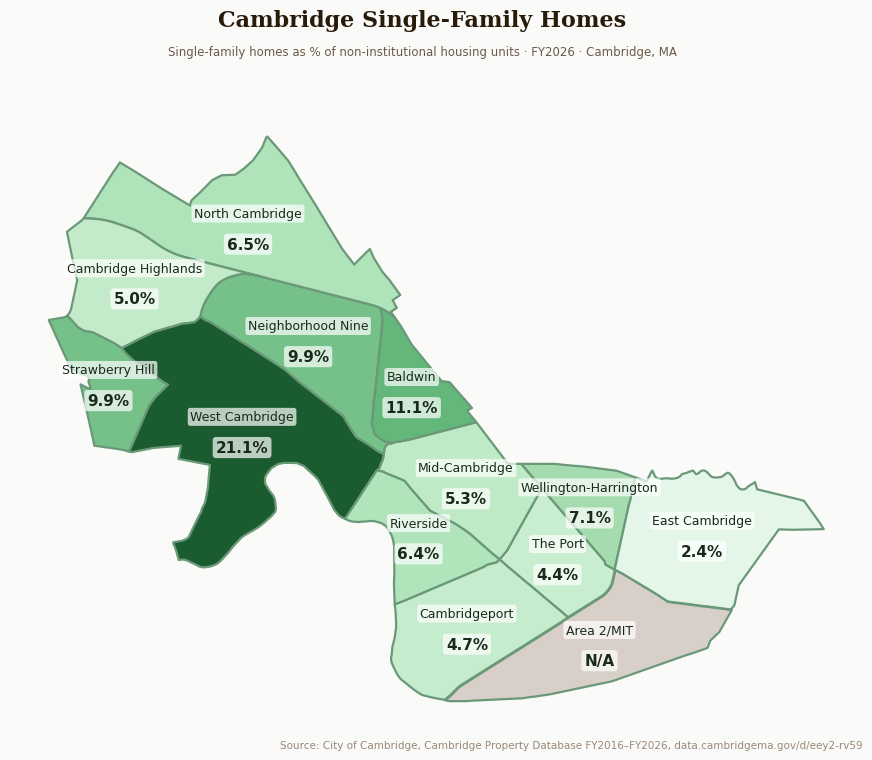

Saved → ../data/out/pct_sfh_map.png


In [9]:
# ── Tweak these ──────────────────────────────────────────────────────────────
TITLE    = "Cambridge Single-Family Homes"
SUBTITLE = "Single-family homes as % of non-institutional housing units · FY2026 · Cambridge, MA"
OUT_PATH = DATA_OUT / "pct_sfh_map.png"
CMAP     = LinearSegmentedColormap.from_list("sfh_green",
               ["#f0faf2", "#b8e8c0", "#4caa68", "#1a5c30"])
GAMMA    = 0.7
VMIN     = 2.0   # anchor below data floor (~3.3%) so full range is used
# ─────────────────────────────────────────────────────────────────────────────

map_gdf = neighborhoods_utm.merge(
    pct_sfh_by_nbhd.reset_index().rename(columns={'pct_sfh': 'value'}),
    on='NAME', how='left',
)

draw_choropleth(
    map_gdf,
    cmap=CMAP,
    norm=PowerNorm(gamma=GAMMA, vmin=VMIN, vmax=map_gdf['value'].max()),
    edge_color="#6a9878",
    txt_color="#1a2a1a",
    label_fn=lambda v: f"{v:.1f}%",
    title=TITLE, subtitle=SUBTITLE, out_path=OUT_PATH,
)


## Choropleth: % single-family homes (by structure)


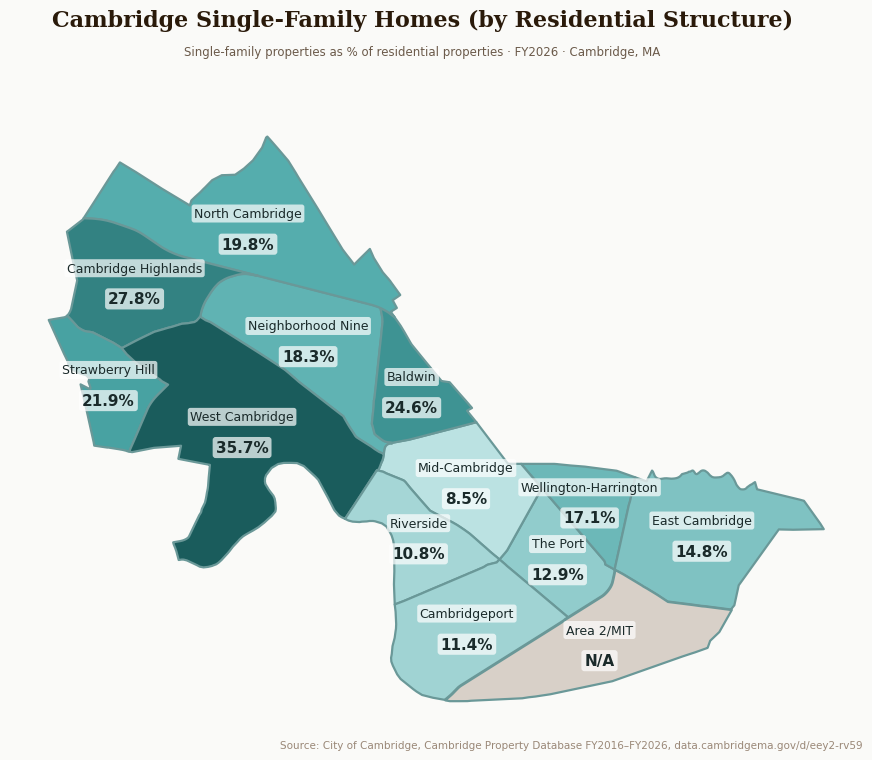

Saved → ../data/out/pct_sfh_structures_map.png


In [10]:
# ── Tweak these ──────────────────────────────────────────────────────────────
TITLE    = "Cambridge Single-Family Homes (by Residential Structure)"
SUBTITLE = "Single-family properties as % of residential properties · FY2026 · Cambridge, MA"
OUT_PATH = DATA_OUT / "pct_sfh_structures_map.png"
CMAP     = LinearSegmentedColormap.from_list("sfh_teal",
               ["#f0fafa", "#b8e0e0", "#4ca8a8", "#1a5c5c"])
GAMMA    = 0.7
VMIN     = 2.0
# ─────────────────────────────────────────────────────────────────────────────

# Structure-based: each assessment record = one property, no unit counting needed
pct_sfh_structures = (
    joined[joined['neighborhood'].notna() & (joined['neighborhood'] != MIT_NAME)]
    .groupby('neighborhood')
    .apply(lambda g: (g['stateclasscode'] == 101).sum() / len(g) * 100)
    .rename('pct_sfh_struct')
    .rename_axis('NAME')
)

map_gdf = neighborhoods_utm.merge(
    pct_sfh_structures.reset_index().rename(columns={'pct_sfh_struct': 'value'}),
    on='NAME', how='left',
)

draw_choropleth(
    map_gdf,
    cmap=CMAP,
    norm=PowerNorm(gamma=GAMMA, vmin=VMIN, vmax=map_gdf['value'].max()),
    edge_color="#6a9898",
    txt_color="#1a2a2a",
    label_fn=lambda v: f"{v:.1f}%",
    title=TITLE, subtitle=SUBTITLE, out_path=OUT_PATH,
)
